# 03-Classification Homework

## Dataset

In [1]:
!wget https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv

--2026-10-19 13:01:27--  https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.111.133, 185.199.108.133, 185.199.109.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.111.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 278746 (272K) [text/plain]
Saving to: ‘course_lead_scoring_2026.csv.3’

course_lead_scoring 100%[===================>] 272.21K  --.-KB/s    in 0.004s  

2026-10-19 13:01:27 (75.7 MB/s) - ‘course_lead_scoring_2026.csv.3’ saved [278746/278746]



In [48]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split 
from sklearn.metrics import mutual_info_score
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction import DictVectorizer

In [3]:
df=pd.read_csv('course_lead_scoring_2026.csv')

In [4]:
df.head().T

,0,1,2,3,4
lead_source,organic_search,social_media,referral,paid_ads,referral
industry,technology,technology,retail,manufacturing,manufacturing
employment_status,employed,employed,employed,student,student
location,europe,south_america,europe,NaN,north_america
annual_income,88160.0,72688.0,44697.0,NaN,24062.0
number_of_courses_viewed,3,3,3,3,4
interaction_count,4,7,4,6,5
lead_score,0.64,0.72,0.58,0.57,0.62
converted,1,1,1,0,1


## Data preparation

In [5]:
df.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [6]:
#uniformization
df.columns=df.columns.str.lower().str.replace(' ', '_')
categorical_columns=list(df.dtypes[df.dtypes=='str'].index)
mask = (df.dtypes=='float64') | (df.dtypes=='int64')        # une Series de booléens, un par colonne               
numerical_columns = list(df.dtypes[mask].index)


In [7]:
print(categorical_columns)
print(numerical_columns)

['lead_source', 'industry', 'employment_status', 'location']
['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score', 'converted']


In [8]:
#checking for missing values
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [11]:
df[categorical_columns]=df[categorical_columns].fillna('NA')
df[numerical_columns]= df[numerical_columns].fillna(0.0)

In [21]:
df.industry.value_counts()

industry
technology       1173
retail            925
healthcare        840
finance           720
education         639
manufacturing     463
NA                240
Name: count, dtype: int64

### correlation matrix

In [27]:
round(df[numerical_columns].corr(method='pearson',numeric_only=True),3)


,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
annual_income,1.000,0.161,0.123,0.229,0.190
number_of_courses_viewed,0.161,1.000,0.722,0.757,0.395
interaction_count,0.123,0.722,1.000,0.916,0.449
lead_score,0.229,0.757,0.916,1.000,0.483
converted,0.190,0.395,0.449,0.483,1.000


<Axes: >

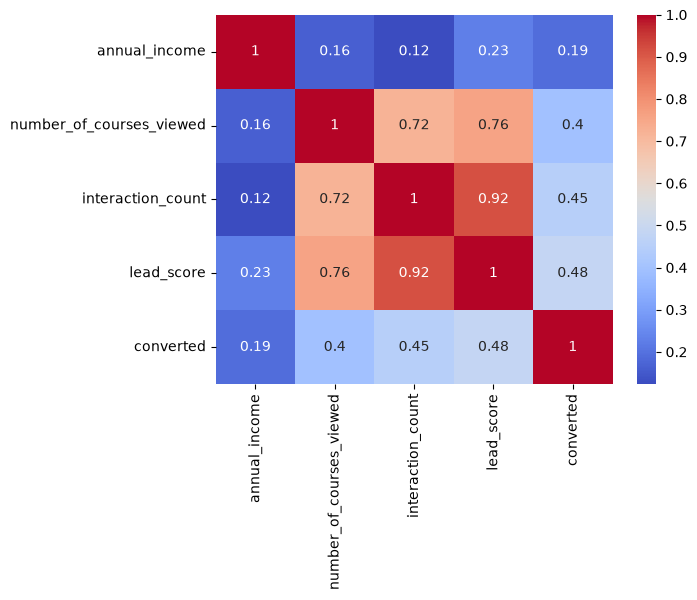

In [29]:
sns.heatmap(round(df[numerical_columns].corr(method='pearson',numeric_only=True),3),cmap='coolwarm',annot=True)


### Split the data

In [32]:
df_full_train,df_test= train_test_split(df,test_size=0.2,random_state= 42)
df_train,df_val=train_test_split(df_full_train,test_size=0.25,random_state=42)

In [38]:
df_train=df_train.reset_index(drop=True)
df_val=df_val.reset_index(drop=True)
df_test=df_test.reset_index(drop=True)


In [ ]:
#isolating the target
y_train=df_train.converted.values
y_test=df_test.converted.values
y_val=df_val.converted.values

AttributeError: 'DataFrame' object has no attribute 'converted'

In [70]:
y_val

array([1, 1, 0, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0,
       1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0,
       0, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1,
       0, 1, 0, 1, 1, 0, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1,
       1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 1, 0,
       1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 1, 0, 1, 1,
       0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0,
       0, 1, 0, 0, 1, 1, 0, 1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 1, 0,
       1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 0, 0,
       1, 1, 0, 0, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1,
       1, 1, 1, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1,
       1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       0, 1, 0, 1, 1, 1, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 0,
       0, 1, 1, 0, 1, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1,

In [56]:
y_full_train=df_full_train.converted.values

In [ ]:
#deleting the target from the dataframes
del df_train['converted']
del df_val['converted']
del df_test['converted']
del df_full_train['converted']

In [42]:
#mutual information score
def mutual_info_converted_score(series):
    return mutual_info_score(series,df_full_train.converted)

In [43]:
mi=df_full_train[categorical_columns].apply(mutual_info_converted_score)
mi.sort_values(ascending=False)

lead_source          0.034761
employment_status    0.020313
industry             0.002898
location             0.001050
dtype: float64

Most important categorical variable :Lead source

## Training a Logistic regression

In [45]:
X_train=df_train.values
X_val=df_val.values
X_test=df_test.values

In [47]:
X_train

array([['paid_ads', 'finance', 'employed', ..., 2, 3, 0.37],
       ['events', 'finance', 'employed', ..., 0, 0, 0.09],
       ['referral', 'NA', 'employed', ..., 2, 5, 0.55],
       ...,
       ['organic_search', 'finance', 'employed', ..., 3, 5, 0.58],
       ['social_media', 'retail', 'employed', ..., 0, 0, 0.03],
       ['paid_ads', 'finance', 'employed', ..., 0, 2, 0.34]],
      shape=(3000, 8), dtype=object)

In [50]:
numerical_columns.remove('converted')

In [64]:
#Hot encoding the categorical features
dv=DictVectorizer(sparse=False)
train_dict= df_train[categorical_columns + numerical_columns].to_dict(orient='records')
X_train=dv.fit_transform(train_dict)

In [65]:
X_train

array([[6.5980e+04, 0.0000e+00, 1.0000e+00, ..., 0.0000e+00, 0.0000e+00,
        2.0000e+00],
       [7.1662e+04, 0.0000e+00, 1.0000e+00, ..., 0.0000e+00, 1.0000e+00,
        0.0000e+00],
       [4.0220e+04, 0.0000e+00, 1.0000e+00, ..., 0.0000e+00, 0.0000e+00,
        2.0000e+00],
       ...,
       [7.1532e+04, 0.0000e+00, 1.0000e+00, ..., 0.0000e+00, 0.0000e+00,
        3.0000e+00],
       [4.8836e+04, 0.0000e+00, 1.0000e+00, ..., 0.0000e+00, 0.0000e+00,
        0.0000e+00],
       [6.8969e+04, 0.0000e+00, 1.0000e+00, ..., 0.0000e+00, 0.0000e+00,
        0.0000e+00]], shape=(3000, 28))

In [68]:
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
model.fit(X_train,y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l

In [77]:
#evalutation
val_dict=df_val[categorical_columns + numerical_columns].to_dict(orient='records')
X_val=dv.transform(val_dict)
y_pred=model.predict_proba(X_val)[:,1]

In [78]:
converted_decision=(y_pred >= 0.5)
(converted_decision == y_val).mean()

np.float64(0.645)